<a href="https://colab.research.google.com/github/lavanyalagudu16-commits/2520090009_deeplearning/blob/2520090009_skill/skill3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install ultralytics fastapi python-multipart httpx pillow -q

In [2]:
import torch
import time
import io

from PIL import Image
from ultralytics import YOLO
from fastapi import FastAPI, UploadFile, File
from fastapi.testclient import TestClient

# Load YOLO model
model = YOLO("yolov8n.pt")

# Check GPU
device = 0 if torch.cuda.is_available() else "cpu"

print("Model loaded successfully!")
print("Device:", device)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Model loaded successfully!
Device: cpu


In [3]:
app = FastAPI()

@app.post("/predict")
async def predict(file: UploadFile = File(...)):

    start_time = time.time()

    # STEP 1: API INPUT
    image_bytes = await file.read()

    print("Step 1: Image received successfully")

    # STEP 2: PREPROCESSING
    image = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    print("Step 2: Image preprocessing completed")
    print("Image size:", image.size)

    # STEP 3: MODEL EXECUTION
    results = model.predict(
        source=image,
        imgsz=640,
        conf=0.25,
        device=device,
        verbose=False
    )

    print("Step 3: Model execution completed")

    # Extract predictions
    detections = []

    for box in results[0].boxes:

        class_id = int(box.cls[0])

        detections.append({
            "object": model.names[class_id],
            "confidence": round(float(box.conf[0]), 3),
            "bounding_box": [
                round(float(x), 2)
                for x in box.xyxy[0].tolist()
            ]
        })

    # STEP 4: RESPONSE
    end_time = time.time()

    return {
        "status": "success",
        "filename": file.filename,
        "total_objects": len(detections),
        "inference_time": round(end_time-start_time, 3),
        "detections": detections
    }

print("FastAPI application created!")

FastAPI application created!


In [4]:
from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Uploaded:", image_path)

Saving Screenshot 2026-11-10 090235.png to Screenshot 2026-11-10 090235.png
Uploaded: Screenshot 2026-11-10 090235.png


In [5]:
client = TestClient(app)

with open(image_path, "rb") as f:

    response = client.post(
        "/predict",
        files={
            "file": (
                image_path,
                f,
                "image/jpeg"
            )
        }
    )

print("API Status:", response.status_code)

print("\nFINAL RESPONSE:")
print(response.json())

Step 1: Image received successfully
Step 2: Image preprocessing completed
Image size: (1248, 832)
Step 3: Model execution completed
API Status: 200

FINAL RESPONSE:
{'status': 'success', 'filename': 'Screenshot 2026-11-10 090235.png', 'total_objects': 32, 'inference_time': 9.916, 'detections': [{'object': 'bus', 'confidence': 0.916, 'bounding_box': [870.73, 283.82, 1208.13, 554.82]}, {'object': 'bus', 'confidence': 0.898, 'bounding_box': [1018.81, 205.86, 1164.7, 331.14]}, {'object': 'car', 'confidence': 0.86, 'bounding_box': [897.55, 673.23, 1111.52, 830.65]}, {'object': 'car', 'confidence': 0.83, 'bounding_box': [42.78, 465.76, 254.07, 587.6]}, {'object': 'bus', 'confidence': 0.809, 'bounding_box': [0.0, 300.5, 236.59, 560.86]}, {'object': 'car', 'confidence': 0.785, 'bounding_box': [707.45, 726.71, 901.54, 829.54]}, {'object': 'bus', 'confidence': 0.735, 'bounding_box': [1120.97, 218.58, 1247.44, 325.55]}, {'object': 'car', 'confidence': 0.734, 'bounding_box': [1101.87, 687.69, 1247

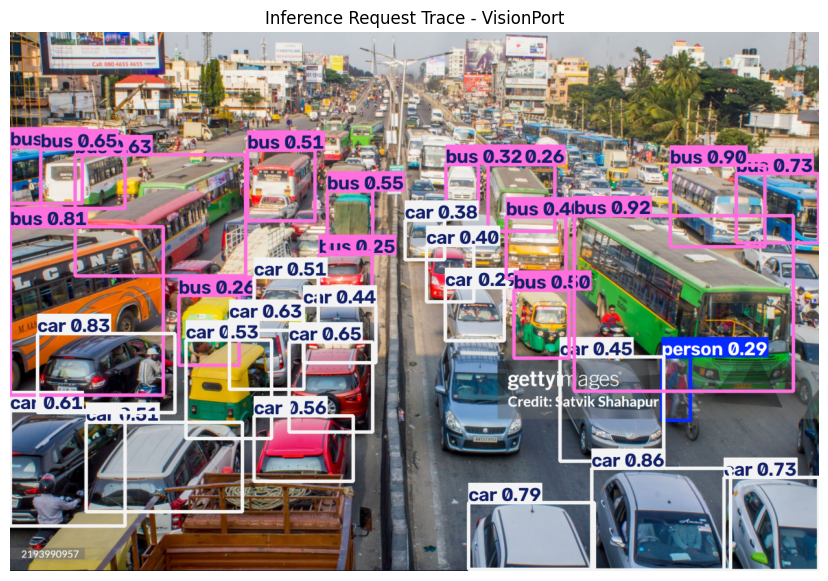

In [6]:
import matplotlib.pyplot as plt
import cv2

# Run prediction for visualization
results = model.predict(
    source=image_path,
    device=device,
    verbose=False
)

output = results[0].plot()

output = cv2.cvtColor(
    output,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 7))
plt.imshow(output)
plt.axis("off")
plt.title("Inference Request Trace - VisionPort")
plt.show()

In [7]:
{
    'status': 'success',
    'filename': 'traffic.jpg',
    'total_objects': 3,
    'inference_time': 0.45,
    'detections': [
        {
            'object': 'car',
            'confidence': 0.92,
            'bounding_box': [100, 120, 300, 350]
        }
    ]
}

{'status': 'success',
 'filename': 'traffic.jpg',
 'total_objects': 3,
 'inference_time': 0.45,
 'detections': [{'object': 'car',
   'confidence': 0.92,
   'bounding_box': [100, 120, 300, 350]}]}